In [23]:
# Imports de ac2
from tensorflow import keras
from keras import layers
import numpy as np

# Recurrent Neural Networks

Conv2D: 

MaxPooling2D:



In [24]:

CLASSES = {
    0: "Absent",
    1: "Unknown",
    2: "Present"
}


class Config:
    # --- RNN ---
    n_mfcc: int = 13
    rnn_frame_step: int = 64       # passo maior => sequências mais curtas (~77)
    win_sec: float=5.0
    frame_len: int=128
    fs_target: int=1000
    seed: int = 42

    @property
    def wav_dir(self): return "data/circor/training_data"

    @property
    def wav_dir_csv(self): return "data/circor/training_data.csv"

In [25]:
from keras import models
from keras import layers

def build_rnn(n_mfcc, fs_target, rnn_frame_step, frame_len, win_sec):
    #Tamanho da janela * banda de frequência 
    win = int(win_sec * fs_target)   
    # rnn_frame_step: divisão do input em sequências
    time_steps = 1 + (win - frame_len) // rnn_frame_step 
    n_features=n_mfcc*3
    model = models.Sequential([
        layers.Input(shape=(time_steps,n_features)),
        layers.Bidirectional(layers.GRU(units=64, return_sequences=True)), #return_sequences=True; as camadas anteriores são passadas para layers seguintes. Essas camadas são passadas como sequências.
        layers.Bidirectional(layers.GRU(units=64, return_sequences=True)),
        layers.Bidirectional(layers.GRU(units=64)), #O output final é ATIVAÇÃO (computado a partir de pesos e inputs).
        layers.Dropout(0.1),
        #Bloco 2: : two-layer NN, fully-connected, c/ funções de ativação Tanh, c/tamanho 60 e 40
        layers.Dense(60, activation='tanh'),
        layers.Dropout(0.1),
        layers.Dense(40, activation='tanh'),
        #OUTPUT
        layers.Dense(len([key for key in CLASSES.values()]), activation='softmax') # 5 segmentation labels per time step
    ])
    return model    


# PatientAggregator

In [26]:
from collections import defaultdict

class PatientAggregator:
    def __init__(self, strategy="mean", k=3, decision="weighted", thresholds=None):
        """
        strategy: 'mean' (baseline) ou 'topk' (melhorado)
        decision: 'weighted' (score * [5,3,1]) ou 'unweighted' (argmax puro)
        thresholds: tuplo opcional (th_present, th_unknown)
        """
        self.strategy = strategy
        self.k = k
        self.decision = decision
        self.thresholds = thresholds

    def aggregate(self, probs, y_win, pids):
            
            """Group windows by patient"""
            groups = defaultdict(list) # diferente de {}
            labels = {}
            for p, y, pid in zip(probs, y_win, pids):
                #Se person_id==NaN, removemos a entrada
                if pd.isna(pid): continue
                pid_int = int(pid)
                groups[pid_int].append(p)
                labels[pid_int] = y
    
            ids = list(groups) #Cria uma lista de índices únicos. A LISTA NÃO ESTÁ ORDENA POR INT.
    
            """
            Calcula o vetor de probabilidades combinadas por classe [Present, Unknown, Absent]
            Combinação das previsões dos modelos ao longo das diferentes windows do paciente.
    
            """
            
            patient_probs = []
            for pid in ids:
    
                wins = np.array(groups[pid])
                n_wins = len(wins)
    
                if self.strategy == "mean":
                    # Baseline original: média aritmética simples
                    p_agg = np.mean(wins, axis=0)
                
                elif self.strategy == "topk":
                    
                    # Versão robusta: Top-k janelas para Present e Unknown
                    eff_k = min(self.k, n_wins)
                    top_pres = np.mean(wins[np.argsort(wins[:, 0])[-eff_k:], 0])
                    top_unk = np.mean(wins[np.argsort(wins[:, 1])[-eff_k:], 1])
                    p_abs = np.mean(wins[:, 2])
    
                    total = top_pres + top_unk + p_abs
                    p_agg = np.array([top_pres, top_unk, p_abs]) / total
                
                else:
                    raise ValueError(f"Estratégia não implementada: {self.strategy}")
    
                #print(pid, p_agg)
                patient_probs.append(p_agg)
    
            """
            Calcula a probabilidade final do paciente para aquela sequência.
            Thresholds: (th_present), (th_unknown)
                (th_present) p[0]: Probabilidade final mínima para classificar como "Sopro cardíaco presente" (0). 
                (th_unknown) p[1]: Probabilidae final m~´inima para classificar como "Sopro cardíaco não foi encontrado" (1)
                - Se o tuplo for fornecido
                - Se o tuplo não fornecido
                    - Adiciona viés às classes se atributo self.decision da classe Aggregator for "weighted"
                    - A probabilidade será o maior valor registado.    
            
            y_pred = np.array(preds) é a coleção de valores previstos.
            """
    
            pr = np.array(patient_probs)
            y_true = np.array([labels[i] for i in ids])
    
            
            # Decisão final
            if self.thresholds is not None:
                th_pres, th_unk = self.thresholds
                preds = [0 if p[0] >= th_pres else (1 if p[1] >= th_unk else 2) for p in pr]
                y_pred = np.array(preds)
            
            else:
                score = pr * METRIC_W if self.decision == "weighted" else pr
                y_pred = score.argmax(axis=1)
    
            #print(y_true, y_pred, pr)
    
            return y_true, y_pred, pr

# Treinar modelo criado na deteção de sopros cardíacos

In [27]:
class PatientWACallback(keras.callbacks.Callback):
        
    def __init__(self, X_val, y_val, pids_val, aggregator):
        super().__init__()
        self.X_val = X_val
        self.y_val = y_val
        self.pids_val = pids_val
        self.aggregator = aggregator

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.X_val, batch_size=128, verbose=0)
        yt, yp, _ = self.aggregator.aggregate(probs, self.y_val, self.pids_val)
        w = METRIC_W[yt]
        wa = float(np.sum(w * (yt == yp)) / np.sum(w))
        if isinstance(logs, dict):
            logs["val_wa"] = wa
        print(f" - val_wa (paciente): {wa:.4f}")


class MurmurTrainer:
    
    def __init__(self, model, weight_mode="smoothed"):
        """weight_mode: 'standard' (inverso clássico), 'smoothed' (raiz quadrada) ou None"""
        self.model = model
        self.weight_mode = weight_mode

    def compute_weights(self, y_train):
        if self.weight_mode is None:
            return None
        counts = np.bincount(y_train, minlength=3).astype(float)
        if self.weight_mode == "standard":
            w = counts.sum() / (3.0 * counts)
        elif self.weight_mode == "smoothed":
            w = np.sqrt(counts.sum() / (3.0 * counts))
            w = w / w.mean()
        return {i: float(w[i]) for i in range(3)}


    def train(self, Xtr, ytr, Xva, yva, pva, aggregator:PatientAggregator, epochs=40, batch_size=64):
        self.model.compile(
            optimizer=keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        callbacks = [
            PatientWACallback(Xva, yva, pva, aggregator),
            keras.callbacks.EarlyStopping(monitor="val_wa", mode="max", patience=8, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1)
        ]

        return self.model.fit(
            Xtr, ytr,
            validation_data=(Xva, yva),
            epochs=epochs,
            batch_size=batch_size,
            class_weight=self.compute_weights(ytr),
            callbacks=callbacks,
            verbose=2
        )
    
    def find_optimal_thresholds(self, probs_val, y_val, pids_val, aggregator):
        """Encontra o par (th_present, th_unknown) que maximiza o WA na validação."""
        yt, _, pr = aggregator.aggregate(probs_val, y_val, pids_val)
        
        best_wa = -1.0
        best_th = (0.33, 0.33)
        
        for th_pres in np.linspace(0.15, 0.75, 61):
            for th_unk in np.linspace(0.15, 0.65, 51):
                preds = np.array([
                    0 if p[0] >= th_pres else (1 if p[1] >= th_unk else 2)
                    for p in pr
                ])
                w = METRIC_W[yt]
                wa = float(np.sum(w * (yt == preds)) / np.sum(w))
                if wa > best_wa:
                    best_wa = wa
                    best_th = (round(float(th_pres), 3), round(float(th_unk), 3))
                    
        return best_th, best_wa

# MLP on full training set

In [28]:
import time

RESULTS:dict[str, dict[str, int | float]] = {}     # experiment name -> summary dict
HISTORIES:dict[str, dict[str, list[float]]] = {}   # experiment name -> keras History.history dict
MODELS:dict[str, keras.Model] = {}      # experiment name -> trained model

def train_model(name, model, train_ds, val_ds, epochs=10, optimizer=None, callbacks=None, verbose=1):
    # Compile + fit a model and log the results under `name`.
    # `optimizer` must be a *new* optimizer object (they keep internal state); default: Adam(1e-3).
    if any(model is m for m in MODELS.values()):
        print(f"WARNING: this model object was already trained; training will CONTINUE from its current weights.\n"
              f"         To start from scratch, create a new model (e.g. call build_mlp() again).")
    if optimizer is None:
        optimizer = keras.optimizers.Adam(learning_rate=1e-3)
    model.compile(optimizer=optimizer,
                  loss=keras.losses.CategoricalCrossentropy(),   # labels are one-hot encoded (Part 2)
                  metrics=["accuracy"])
    t0 = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        callbacks=callbacks, verbose=verbose)
    seconds = time.time() - t0
    h = history.history
    HISTORIES[name] = h
    MODELS[name] = model
    RESULTS[name] = dict(
        params=model.count_params(),
        epochs=len(h["loss"]),
        train_acc=h["accuracy"][-1],
        val_acc=h["val_accuracy"][-1],
        best_val_acc=max(h["val_accuracy"]),
        val_loss=h["val_loss"][-1],
        min_val_loss=min(h["val_loss"]),
        gap=h["accuracy"][-1] - h["val_accuracy"][-1],
        seconds=round(seconds, 1),
    )
    print(f"{name:<38} train acc {h['accuracy'][-1]:.4f} | val acc {h['val_accuracy'][-1]:.4f}"
          f" | {model.count_params():>9,d} params | {seconds:5.1f}s")
    return history


In [29]:
import os
from dotenv import load_dotenv

#LOAD current environment params:
load_dotenv('./params/param_1.env')
MODEL_TITLE=os.getenv('MODEL_TITLE')
SEED=int(str(os.getenv('SEED')))
METRIC_W=np.array([5, 3, 1], dtype=np.float32)

In [30]:
"""
Funções opcionais one_hot(), make_ds(). Fazem encoding das classes, mas como os valores do dicionário CLASSES já são int.

import tensorflow as tf
AUTOTUNE = tf.data.AUTOTUNE


def one_hot(y):
    return keras.utils.to_categorical(y, num_classes=len([k for k in CLASSES.values()]))  

def make_ds(x, y, batch_size=128, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x, one_hot(y)))
    if shuffle:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

"""

'\nFunções opcionais one_hot(), make_ds(). Fazem encoding das classes, mas como os valores do dicionário CLASSES já são int.\n\nimport tensorflow as tf\nAUTOTUNE = tf.data.AUTOTUNE\n\n\ndef one_hot(y):\n    return keras.utils.to_categorical(y, num_classes=len([k for k in CLASSES.values()]))  \n\ndef make_ds(x, y, batch_size=128, shuffle=False):\n    ds = tf.data.Dataset.from_tensor_slices((x, one_hot(y)))\n    if shuffle:\n        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)\n    return ds.batch(batch_size).prefetch(AUTOTUNE)\n\n'

In [31]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
RUN_FOLDER=None

def plot_histories(names, model_title=None, ylim_loss=None, save=False):
    # Loss and accuracy curves for several experiments. Dashed = train, solid = validation.
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    for i, name in enumerate(names):
        h = HISTORIES[name]
        c = f"C{i}"
        
        ep = np.arange(1, len(h["loss"]) + 1)
        axes[0].plot(ep, h["loss"], "--", color="blue", alpha=0.7)
        axes[0].plot(ep, h["val_loss"], "-", color="blue", label=name)
        k = int(np.argmin(h["val_loss"]))                       # epoch with the lowest validation loss
        axes[0].plot(k + 1, h["val_loss"][k], "o", color=c, markersize=7, markeredgecolor="black")
        
        axes[1].plot(ep, h["accuracy"], "--", color="orange", alpha=0.7)
        axes[1].plot(ep, h["val_accuracy"], "-", color="orange", label=name)
    
    axes[0].set_title(f"Loss plot {model_title}")
    axes[1].set_title(f"Accuracy plot {model_title}")
    
    for ax in axes:
        ax.set_xlabel("epoch"); ax.grid(alpha=0.3)

    #Definição dos tamanhos dos eixos
    if ylim_loss is not None:
        axes[0].set_ylim(*ylim_loss)
    
  
    axes[0].legend(
        [
            Line2D([], [], ls="--", color="gray"), 
            Line2D([], [], ls="-", color="gray"),
            Line2D([], [], ls="", marker="o", color="gray", markeredgecolor="black")
        ],
        ["training", "validation", "min. validation loss"], 
        fontsize=8
    )

    if (save and (RUN_FOLDER!=None)): 
        fig.savefig(RUN_FOLDER/"Loss_Accuracy_Plot")

    plt.tight_layout()
    plt.show()


In [32]:
from datetime import datetime, timezone
from pathlib import Path
def export_keras_model(MODELS:dict[str,keras.Model], output_path:Path):
    for key,value in MODELS.items():
        model:keras.Model= value
        model.save(output_path/f"{key}.keras")
    

def export_results(RESULTS:str):
    user_name = str(os.getenv("USER") or os.getenv("USERNAME"))
    local_time = datetime.now().astimezone().strftime("%d-%m_%H-%M")
    output_dir=""+local_time+"_"+user_name
    output_path=Path(RESULTS) / Path(output_dir)
    Path.mkdir(output_path, parents=True, exist_ok=True)
    if (output_path.exists):
        export_keras_model(MODELS=MODELS, output_path=output_path)
    return output_path

Xtr=(16688, 77, 39), ytr=(16688,), Xva=(3644, 77, 39), yva=(3644,), pva=(3644,)
Epoch 1/10
 - val_wa (paciente): 0.5222
261/261 - 57s - 218ms/step - accuracy: 0.7465 - loss: 0.5426 - val_accuracy: 0.6951 - val_loss: 0.7901 - val_wa: 0.5222 - learning_rate: 0.0010
Epoch 2/10
 - val_wa (paciente): 0.6111
261/261 - 41s - 158ms/step - accuracy: 0.8301 - loss: 0.4250 - val_accuracy: 0.8057 - val_loss: 0.6333 - val_wa: 0.6111 - learning_rate: 0.0010
Epoch 3/10
 - val_wa (paciente): 0.6593
261/261 - 41s - 156ms/step - accuracy: 0.8359 - loss: 0.3754 - val_accuracy: 0.7912 - val_loss: 0.6164 - val_wa: 0.6593 - learning_rate: 0.0010
Epoch 4/10
 - val_wa (paciente): 0.7296
261/261 - 39s - 149ms/step - accuracy: 0.8418 - loss: 0.3388 - val_accuracy: 0.7810 - val_loss: 0.6152 - val_wa: 0.7296 - learning_rate: 0.0010
Epoch 5/10
 - val_wa (paciente): 0.7593
261/261 - 40s - 155ms/step - accuracy: 0.8548 - loss: 0.2953 - val_accuracy: 0.7761 - val_loss: 0.6165 - val_wa: 0.7593 - learning_rate: 0.0010


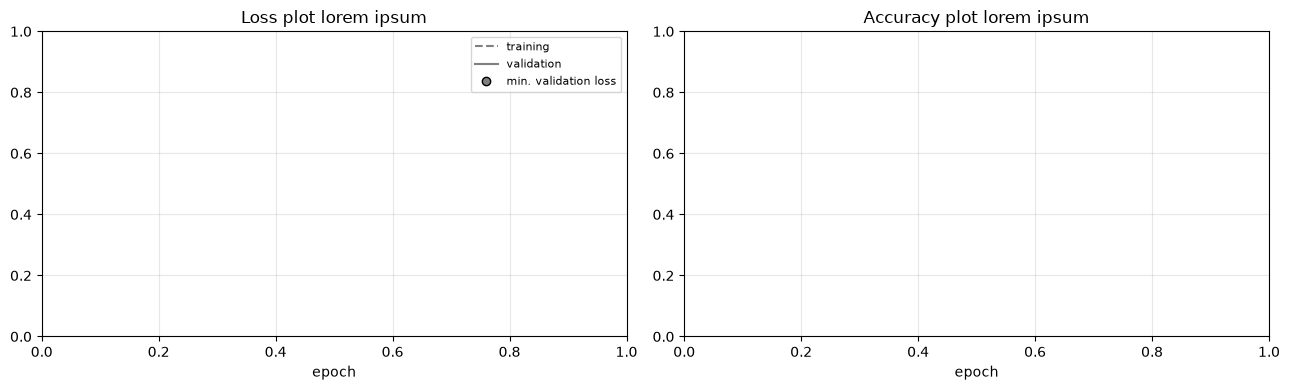

In [33]:
from pathlib import Path
import pandas as pd

keras.utils.set_random_seed(42)

#Iniciar o folder de resultados para esta run
RUN_FOLDER=export_results(RESULTS=str(os.getenv('RESULTS')))

"""
Carregar dados pré-processados

"""
def load_split(name, CACHE):
    d = np.load(CACHE / f"{name}.npz")
    info = pd.read_csv(CACHE / f"{name}_info.csv", dtype={"pid": str})
    #d["cnn2d"] extrai do zip .npz o numpy array "cnn2d"
    return d["rnn"], d["y"], info["pid"].values
 
CACHE=Path(str(os.getenv("CACHE")))
Xtr, ytr, ptr = load_split("train", CACHE=CACHE)
Xva, yva, pva = load_split("val", CACHE=CACHE)


"""
==Converte NumpyArray em tf.data==

suffle: reorganização de dados 
.batch(batch_size): agrupa amostras em mini-batches (128)
.prefetch(AUTOTUNE): prepara os dados da próxima batch 

"""

Xtr_rnn=Xtr.astype("float32")
Xva_rnn=Xva.astype("float32")

#== MODEL DESIGN ==#
CFG=Config()    
rnn_model=build_rnn(
    n_mfcc=CFG.n_mfcc, 
    fs_target=CFG.fs_target, 
    rnn_frame_step=CFG.rnn_frame_step, 
    frame_len=CFG.frame_len, 
    win_sec=CFG.win_sec
)

#== Patient Aggregator ==#
agg_mean = PatientAggregator(strategy="mean",k=3, decision="weighted", thresholds=None)
#== Adicionar o modelo à classe #
trainer=MurmurTrainer(model=rnn_model,weight_mode="smoothed")

#Print the model arrays#
print(f"Xtr={Xtr_rnn.shape}, ytr={ytr.shape}, Xva={Xva_rnn.shape}, yva={yva.shape}, pva={np.asarray(pva).shape}")

trainer.train(
    Xtr=Xtr_rnn,
    ytr=ytr,
    Xva=Xva_rnn,
    yva=yva,
    pva=pva,
    aggregator=agg_mean,
    epochs=10,
    batch_size=64
)

#==CALL MODEL TRAIN==#
print("train:", Xtr.shape, "val:", Xva.shape)
print("RNN_train:", Xtr_rnn.shape, "RNN_val:", Xva_rnn.shape)
print("REQUIRED RNN_model_shape: ", rnn_model.input_shape)

#== Export results ==#

#Loss, Accuracy plot

plot_histories(names=list(HISTORIES.keys()), model_title=MODEL_TITLE, save=True)
